# Reconstrucción 3D de un aula con Gaussian Splatting
**Introducción a los Vehículos Inteligentes** · Proyecto final

A partir de **un solo video** filmado con el celular reconstruimos en 3D un aula de la facultad y la podemos ver desde cualquier punto de vista. No usamos LiDAR ni conocemos los parámetros de la cámara.

El método es **3D Gaussian Splatting (3DGS)**: la escena se representa con millones de "manchas" 3D semitransparentes (*gaussianas*), cada una con posición, forma, orientación, opacidad y color. Se optimizan para que, al proyectarlas sobre la imagen, se parezcan a las fotos reales. Para entrenarlas hay que saber **desde dónde se sacó cada foto**, y eso lo resuelve COLMAP con *Structure from Motion*.

Pasos:
1. Parámetros y video
2. Extracción de frames + **Structure from Motion con COLMAP** (poses de cámara y nube de puntos dispersa)
3. Análisis del resultado de SfM (trayectoria, error de reproyección)
4. Entrenamiento de **3DGS** (Splatfacto de Nerfstudio)
5. Evaluación: PSNR / SSIM / LPIPS en frames que no se usaron para entrenar
6. Recorrido renderizado (video)
7. Exportación y análisis de las gaussianas
8. Resumen y guardado de resultados

| Concepto de la materia | Dónde aparece |
|---|---|
| Puntos característicos SIFT, matching, RANSAC (Unidad III) | COLMAP en GPU (paso 2) |
| Estimación del movimiento de la cámara y de la estructura 3D (Unidad V) | poses y nube dispersa (pasos 2 y 3) |
| Localización | la trayectoria estimada de la cámara es la del "vehículo" |

**Cómo usarlo:** subir el video a `Mi unidad` de Drive, elegir *Entorno de ejecución → Cambiar tipo → GPU* y ejecutar las celdas en orden. Con una GPU L4 o A100 tarda unos 25–40 minutos en total, casi todo de entrenamiento. Al terminar, **guardar el cuaderno con las salidas** (*Archivo → Guardar*) para que los resultados queden dentro del `.ipynb`.

## 0. Instalación
- **pycolmap-cuda12**: COLMAP 4 como librería de Python, **compilado con CUDA**. Lo usamos para el Structure from Motion: SIFT y matching corren en la GPU, y la reconstrucción usa **GLOMAP** (SfM global), que es mucho más rápido que el SfM incremental clásico.
- **Nerfstudio**: framework que trae **Splatfacto**, su implementación de 3D Gaussian Splatting.
- **gsplat**: rasterizador de gaussianas en CUDA que usa Splatfacto.
- **trimesh**: para leer y escribir nubes de puntos `.ply`.

Al instalar `nerfstudio`, pip muestra avisos de conflictos de versiones (numpy, protobuf). Son normales en Colab y no impiden que funcione.

In [ ]:
!pip install -q --upgrade pip
!pip install -q nerfstudio gsplat trimesh
!pip uninstall -q -y pycolmap
!pip install -q pycolmap-cuda12==4.2.1

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grain 0.2.18 requires protobuf>=5.28.3, but you have protobuf 3.20.3 which is incompatible.
googleapis-common-protos 1.76.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
tensorflow-metadata 1.21.0 requires protobuf>=4.25.2; python_version >= "3.11", but you have protobuf 3.20.3 which is incompatible.
google-cloud-translate 3.28.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 3.20.3 which is incompatible.
google-cloud-language 2.22.0 requires protobuf<8.0.0,>

In [ ]:
# Comprobamos la GPU y dejamos registradas las versiones usadas
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip list 2>/dev/null | grep -i -E "^(nerfstudio|gsplat|torch) "
!python -c "import pycolmap; print('pycolmap', pycolmap.__version__, '| CUDA:', pycolmap.has_cuda)"

name, memory.total [MiB]
NVIDIA L4, 23034 MiB
gsplat                                1.4.0
nerfstudio                            1.1.5
torch                                 2.14.1+cu130
pycolmap 4.2.1 | CUDA: True


## 1. Parámetros y video
Lo único que hay que tocar es esta celda. El video se lee directo desde **Google Drive** (la primera vez Colab pide permiso).

- `FRAMES_OBJETIVO`: de todo el video se sacan unos 300 frames equiespaciados. Con más frames COLMAP tarda mucho más; con menos puede perder cobertura.
- `ITERACIONES`: 30000 es el valor estándar de 3DGS. Para probar rápido se puede poner 7000.
- `LADO_MAX`: los frames se achican a 1600 px de lado mayor. Es la resolución máxima con la que Nerfstudio entrena sin pedir que se reduzcan las imágenes.

In [ ]:
%cd /content
import os, glob, json, time, shutil, struct
import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount("/content/drive")

# ---------- parámetros (lo único que hay que tocar) ----------
VIDEO = "/content/drive/MyDrive/video2.MOV"   # ruta del video dentro de tu Drive
NOMBRE = "mi_aula"                            # nombre de la escena
FRAMES_OBJETIVO = 800                         # cuántos frames se sacan del video (300 alcanzan para un video corto)
ITERACIONES = 30000                           # pasos de entrenamiento (7000 sirve para una prueba rápida)
LADO_MAX = 1600                               # lado mayor de los frames en píxeles (Nerfstudio entrena a esta resolución)
# --------------------------------------------------------------

DATA = f"/content/data/{NOMBRE}"     # acá queda el video procesado (frames + COLMAP)
SALIDA = "/content/resultados"       # acá juntamos todo lo que vamos a entregar
os.makedirs(SALIDA, exist_ok=True)
RESUMEN = {}                         # diccionario donde vamos guardando los números para la tabla final

assert os.path.exists(VIDEO), "No encuentro el video: revisá la ruta en VIDEO"
print("video:", VIDEO)

/content
Mounted at /content/drive
video: /content/drive/MyDrive/video2.MOV


In [ ]:
# Datos del video: resolución, cuadros por segundo y duración
!ffprobe -v error -select_streams v:0 -show_entries stream=width,height,r_frame_rate,duration,nb_frames -of default=nw=1 "{VIDEO}"

width=1920
height=1080
r_frame_rate=60000/1001
duration=119.881667
nb_frames=7186


## 2. Frames y Structure from Motion (COLMAP 4 en GPU + GLOMAP)
1. **Extraer frames** del video con ffmpeg: tomamos uno cada *k* frames para quedarnos con unos `FRAMES_OBJETIVO`.
2. **SIFT en GPU**: detecta puntos característicos y calcula un descriptor de 128 valores para cada uno.
3. **Matching secuencial en GPU**: cada frame se compara con los siguientes, porque vienen de un video (vecinos en el tiempo).
4. **Verificación geométrica con RANSAC**: descarta los matches incorrectos usando la geometría entre dos vistas (matriz fundamental / esencial).
5. **SfM global (GLOMAP)**: en vez de agregar cámaras de a una como el SfM incremental, primero estima **todas las rotaciones juntas** (*rotation averaging*), después **todas las posiciones y los puntos 3D** en un solo problema (*global positioning*) y al final hace un **bundle adjustment** global que minimiza el **error de reproyección**. También estima la focal y la distorsión de la lente, por eso no hace falta calibrar la cámara.
6. Guardamos el resultado en `transforms.json`, el formato que lee Nerfstudio.

Es el problema de SLAM de la materia, pero resuelto **offline** con todo el video junto (*Full SLAM*).

In [ ]:
import subprocess
!rm -rf "{DATA}"
os.makedirs(f"{DATA}/images", exist_ok=True)

# cuántos frames tiene el video, para tomar uno cada "cada" frames
salida = subprocess.run(["ffprobe", "-v", "error", "-select_streams", "v:0", "-show_entries", "stream=nb_frames",
                         "-of", "csv=p=0", VIDEO], capture_output=True, text=True).stdout.strip()
salida = salida.replace("\n", ",").split(",")[0].strip(); total = int(salida) if salida.isdigit() else 30 * FRAMES_OBJETIVO
cada = max(1, total // FRAMES_OBJETIVO)

# ffmpeg respeta la rotación del video del celular; achicamos para que el lado mayor sea LADO_MAX
escala = f"scale='if(gt(iw,ih),{LADO_MAX},-2)':'if(gt(iw,ih),-2,{LADO_MAX})'"
subprocess.run(["ffmpeg", "-loglevel", "error", "-i", VIDEO, "-vf", f"select=not(mod(n\\,{cada})),{escala}",
                "-fps_mode", "vfr", "-q:v", "2", f"{DATA}/images/frame_%05d.jpg"], check=True)
print("frames del video: %d | tomamos uno cada %d | frames extraídos: %d" % (total, cada, len(os.listdir(f"{DATA}/images"))))

frames del video: 7186 | tomamos uno cada 8 | frames extraídos: 899


In [ ]:
import pycolmap
import trimesh

GPU = pycolmap.has_cuda
DISPOSITIVO = pycolmap.Device.cuda if GPU else pycolmap.Device.cpu
print("pycolmap", pycolmap.__version__, "| usando", "GPU (CUDA)" if GPU else "CPU")

os.makedirs(f"{DATA}/colmap/sparse", exist_ok=True)
db = f"{DATA}/colmap/database.db"
tiempos = {}

# 1) SIFT: una sola cámara para todo el video, modelo OPENCV (pinhole + distorsión radial y tangencial)
t = time.time()
lector = pycolmap.ImageReaderOptions()
lector.camera_model = "OPENCV"
pycolmap.extract_features(db, f"{DATA}/images", camera_mode=pycolmap.CameraMode.SINGLE,
                          reader_options=lector, device=DISPOSITIVO)
tiempos["sift_s"] = round(time.time() - t, 1)

# 2) Matching secuencial: cada frame contra los 15 siguientes (y algunos más lejanos, en saltos crecientes)
t = time.time()
pares = pycolmap.SequentialPairingOptions()
pares.overlap = 15
pares.quadratic_overlap = True
pycolmap.match_sequential(db, pairing_options=pares, device=DISPOSITIVO)
tiempos["matching_s"] = round(time.time() - t, 1)

# 3) SfM global con GLOMAP
t = time.time()
modelos = pycolmap.global_mapping(db, f"{DATA}/images", f"{DATA}/colmap/sparse")
tiempos["glomap_s"] = round(time.time() - t, 1)
assert len(modelos) > 0, "GLOMAP no pudo reconstruir: revisá que el video tenga textura y que la cámara se mueva despacio"

# si quedaron varios modelos sueltos, nos quedamos con el que tiene más cámaras
rec = max(modelos.values(), key=lambda r: r.num_reg_images())
os.makedirs(f"{DATA}/colmap/sparse/0", exist_ok=True)
rec.write(f"{DATA}/colmap/sparse/0")

RESUMEN["tiempo_colmap_min"] = round(sum(tiempos.values()) / 60, 1)
print("tiempos (s):", tiempos)
print(rec.summary())

pycolmap 4.2.1 | usando GPU (CUDA)
tiempos (s): {'sift_s': 31.8, 'matching_s': 548.4, 'glomap_s': 5833.8}
Reconstruction:
	num_rigs = 1
	num_cameras = 1
	num_frames = 899
	num_reg_frames = 899
	num_images = 899
	num_points3D = 700338
	num_observations = 6275480
	mean_track_length = 8.96064
	mean_observations_per_image = 6980.51
	mean_reprojection_error = 0.356256


### De COLMAP a Nerfstudio (`transforms.json`)
Para cada cámara COLMAP da la transformación **mundo → cámara** con la convención de OpenCV (la cámara mira hacia +z, con y hacia abajo). Nerfstudio pide la inversa, **cámara → mundo**, con la convención de OpenGL (mira hacia −z, con y hacia arriba): invertimos la matriz y cambiamos el signo de los ejes y y z de la cámara. Guardamos también los parámetros de la cámara y la nube dispersa, que Nerfstudio usa como punto de partida de las gaussianas.

In [ ]:
cam = rec.cameras[next(iter(rec.cameras))]
fx, fy, cx, cy, k1, k2, p1, p2 = cam.params        # parámetros del modelo OPENCV

cuadros = []
for iid in sorted(rec.reg_image_ids(), key=lambda i: rec.images[i].name):
    im = rec.images[iid]
    w2c = np.eye(4)
    w2c[:3, :4] = im.cam_from_world().matrix()      # mundo -> cámara (OpenCV)
    c2w = np.linalg.inv(w2c)                        # cámara -> mundo
    c2w[:3, 1:3] *= -1                              # OpenCV -> OpenGL
    cuadros.append({"file_path": "images/" + im.name, "transform_matrix": c2w.tolist(), "colmap_im_id": int(iid)})

xyz = np.array([p.xyz for p in rec.points3D.values()])
rgb = np.array([p.color for p in rec.points3D.values()], dtype=np.uint8)
trimesh.PointCloud(xyz, colors=rgb).export(f"{DATA}/sparse_pc.ply")

transforms = {"w": cam.width, "h": cam.height, "fl_x": fx, "fl_y": fy, "cx": cx, "cy": cy,
              "k1": k1, "k2": k2, "p1": p1, "p2": p2, "camera_model": "OPENCV",
              "frames": cuadros, "ply_file_path": "sparse_pc.ply"}
with open(f"{DATA}/transforms.json", "w") as f:
    json.dump(transforms, f, indent=2)
print("transforms.json con %d cámaras y %d puntos 3D" % (len(cuadros), len(xyz)))

transforms.json con 899 cámaras y 700338 puntos 3D


### Calidad de los frames
Un video movido da frames borrosos, y los frames borrosos son una de las causas más comunes de un splat de mala calidad. Medimos la **nitidez** de cada frame con la varianza del laplaciano: si el frame es borroso casi no tiene bordes y la varianza es baja. Marcamos como "borroso" a un frame con menos de la mitad de la nitidez mediana (es un criterio práctico, no un estándar).

frames extraídos: 899


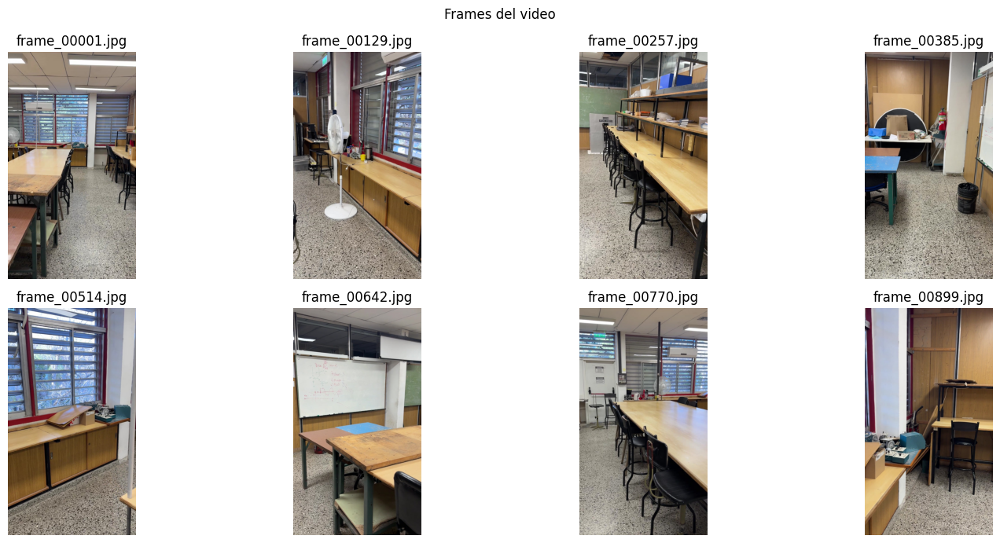

In [ ]:
frames = sorted(glob.glob(f"{DATA}/images/*"))
RESUMEN["frames_extraidos"] = len(frames)
print("frames extraídos:", len(frames))

# ocho frames equiespaciados para ver qué recorrido hizo la cámara
idx = np.linspace(0, len(frames) - 1, 8).astype(int)
fig, ejes = plt.subplots(2, 4, figsize=(16, 7))
for a, i in zip(ejes.ravel(), idx):
    a.imshow(plt.imread(frames[i]))
    a.set_title(os.path.basename(frames[i]))
    a.axis("off")
plt.suptitle("Frames del video")
plt.tight_layout()
plt.savefig(f"{SALIDA}/frames.png", dpi=100)
plt.show()

frames borrosos: 41 de 899 (4.6 %)


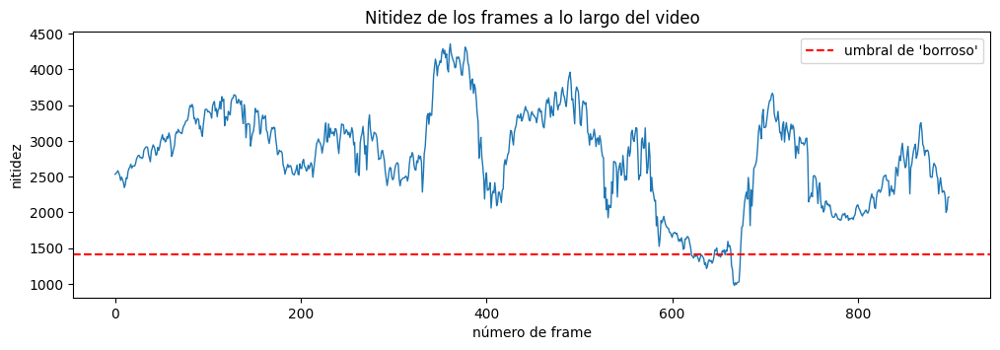

In [ ]:
# Nitidez de cada frame (varianza del laplaciano sobre la imagen reducida)
nitidez = []
for f in frames:
    g = cv2.imread(f, cv2.IMREAD_REDUCED_GRAYSCALE_4)
    nitidez.append(cv2.Laplacian(g, cv2.CV_64F).var())
nitidez = np.array(nitidez)

umbral = 0.5 * np.median(nitidez)
borrosos = nitidez < umbral
RESUMEN["frames_borrosos_%"] = round(float(100 * borrosos.mean()), 1)
print("frames borrosos: %d de %d (%.1f %%)" % (borrosos.sum(), len(nitidez), 100 * borrosos.mean()))

plt.figure(figsize=(12, 3.5))
plt.plot(nitidez, lw=1)
plt.axhline(umbral, color="r", ls="--", label="umbral de 'borroso'")
plt.xlabel("número de frame"); plt.ylabel("nitidez")
plt.title("Nitidez de los frames a lo largo del video")
plt.legend()
plt.savefig(f"{SALIDA}/nitidez.png", dpi=100)
plt.show()

## 3. Resultado del SfM: trayectoria de la cámara y nube dispersa
Con `transforms.json` leemos la **pose de cada frame** (dónde estaba la cámara y hacia dónde miraba) y con `sparse_pc.ply` la **nube de puntos dispersa**. Esa nube es además el punto de partida del entrenamiento: cada punto va a ser una gaussiana inicial.

Para cada punto 3D, COLMAP guarda su **error de reproyección** (distancia en píxeles entre donde se ve el punto en la imagen y donde lo proyecta el modelo) y en cuántas imágenes se lo vio (*track*). Como referencia, un error medio menor a ~1 px indica un SfM consistente.

cámaras con pose: 899 de 899 frames
modelo de cámara: OPENCV | resolución: 900 x 1600
focal estimada: fx = 1358 px | fy = 1348 px
puntos 3D de la nube dispersa: 700338


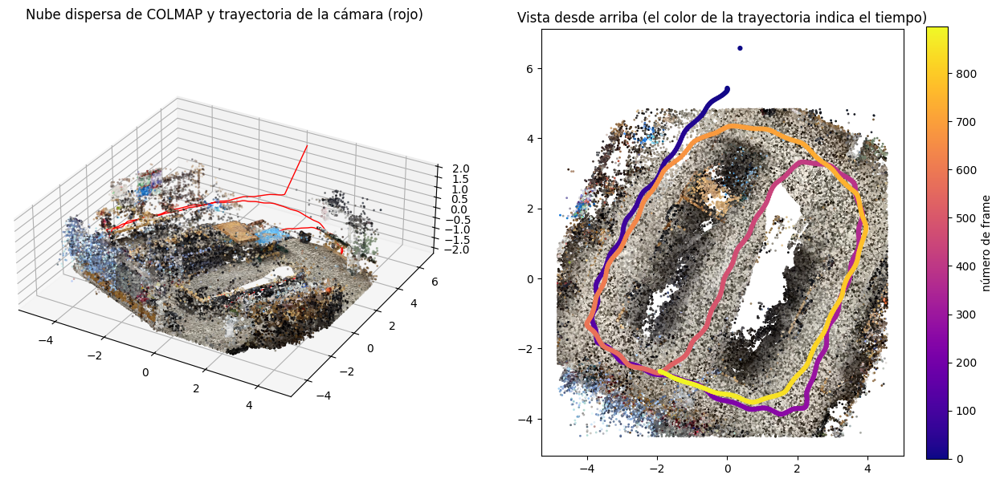

longitud de la trayectoria (unidades de COLMAP, aún sin escala real): 57.72


In [ ]:
with open(f"{DATA}/transforms.json") as f:
    T = json.load(f)

poses = np.array([fr["transform_matrix"] for fr in T["frames"]])   # pose de cada cámara (4x4, cámara -> mundo)
centros = poses[:, :3, 3]                                           # posición de la cámara en cada frame
RESUMEN["camaras_con_pose"] = len(poses)
print("cámaras con pose:", len(poses), "de", len(frames), "frames")
print("modelo de cámara:", T.get("camera_model"), "| resolución:", T["w"], "x", T["h"])
print("focal estimada: fx = %.0f px | fy = %.0f px" % (T["fl_x"], T["fl_y"]))

nube = trimesh.load(f"{DATA}/{T.get('ply_file_path', 'sparse_pc.ply')}")
puntos = np.asarray(nube.vertices)
try:
    colores = np.asarray(nube.colors)[:, :3] / 255
except Exception:
    colores = np.full((len(puntos), 3), 0.5)
RESUMEN["puntos_3d_colmap"] = len(puntos)
print("puntos 3D de la nube dispersa:", len(puntos))

# COLMAP no sabe dónde es "arriba": usamos el promedio del eje "arriba" de las cámaras como vertical (solo para graficar)
arriba = poses[:, :3, 1].mean(axis=0)
arriba /= np.linalg.norm(arriba)
eje = np.cross(arriba, [0, 0, 1])
ang = np.arccos(np.clip(arriba[2], -1, 1))
R = trimesh.transformations.rotation_matrix(ang, eje)[:3, :3] if np.linalg.norm(eje) > 1e-9 else np.eye(3)
puntos_g = puntos @ R.T
centros_g = centros @ R.T

# recorte de outliers para que los ejes no se estiren por puntos muy lejanos
lo, hi = np.percentile(puntos_g, 1, axis=0), np.percentile(puntos_g, 99, axis=0)
ok = np.all((puntos_g >= lo) & (puntos_g <= hi), axis=1)

fig = plt.figure(figsize=(16, 7))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.scatter(*puntos_g[ok].T, c=colores[ok], s=1)
ax.plot(*centros_g.T, "r-", lw=1)
ax.set_box_aspect(np.ptp(puntos_g[ok], axis=0))
ax.set_title("Nube dispersa de COLMAP y trayectoria de la cámara (rojo)")

ax2 = fig.add_subplot(1, 2, 2)
ax2.scatter(puntos_g[ok, 0], puntos_g[ok, 1], c=colores[ok], s=1)
sc = ax2.scatter(centros_g[:, 0], centros_g[:, 1], c=np.arange(len(centros_g)), cmap="plasma", s=12)
plt.colorbar(sc, label="número de frame")
ax2.set_aspect("equal")
ax2.set_title("Vista desde arriba (el color de la trayectoria indica el tiempo)")
plt.savefig(f"{SALIDA}/sfm.png", dpi=100)
plt.show()

largo_tray = np.linalg.norm(np.diff(centros, axis=0), axis=1).sum()
print("longitud de la trayectoria (unidades de COLMAP, aún sin escala real): %.2f" % largo_tray)

error de reproyección medio: 0.356 px (mediana 0.288 px)
cada punto se ve en promedio en 9.0 imágenes


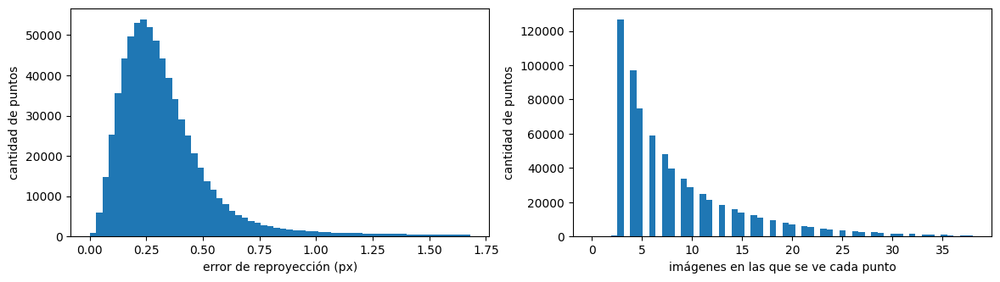

In [ ]:
# Error de reproyección y largo de track (en cuántas imágenes se ve) de cada punto 3D
errores = np.array([p.error for p in rec.points3D.values()])
largos = np.array([p.track.length() for p in rec.points3D.values()])
RESUMEN["error_reproyeccion_medio_px"] = round(float(errores.mean()), 3)
RESUMEN["track_medio_imagenes"] = round(float(largos.mean()), 1)
print("error de reproyección medio: %.3f px (mediana %.3f px)" % (errores.mean(), np.median(errores)))
print("cada punto se ve en promedio en %.1f imágenes" % largos.mean())

fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
ax[0].hist(errores, bins=60, range=(0, np.percentile(errores, 99)))
ax[0].set_xlabel("error de reproyección (px)"); ax[0].set_ylabel("cantidad de puntos")
ax[1].hist(largos, bins=60, range=(0, np.percentile(largos, 99)))
ax[1].set_xlabel("imágenes en las que se ve cada punto"); ax[1].set_ylabel("cantidad de puntos")
plt.savefig(f"{SALIDA}/error_reproyeccion.png", dpi=100)
plt.show()

## 4. Entrenamiento: 3D Gaussian Splatting (Splatfacto)
Cada gaussiana tiene **posición** (3), **escala** (3) y **rotación** (cuaternión), que definen un elipsoide, más **opacidad** y **color**. El color se guarda con *armónicos esféricos*, así que puede cambiar según la dirección desde la que se mira (brillos, reflejos suaves).

El entrenamiento repite, por cada frame de entrenamiento:
1. **Inicialización**: cada punto de la nube dispersa de COLMAP se convierte en una gaussiana.
2. **Renderizado diferenciable**: cada gaussiana 3D se proyecta a la imagen como una elipse 2D y se mezclan de adelante hacia atrás (*alpha blending*). Se hace por *tiles* en la GPU con gsplat.
3. **Pérdida**: se compara el render con la foto real (L1 + SSIM) y por descenso del gradiente se ajustan todos los parámetros de las gaussianas.
4. **Densificación adaptativa**: cada cierto número de pasos se *dividen o clonan* las gaussianas donde hay mucho error y se *eliminan* las casi transparentes. Por eso la cantidad de gaussianas crece durante el entrenamiento.

Las imágenes se guardan directamente en la memoria de la GPU (`cache-images gpu`) para no copiarlas en cada paso.

Nerfstudio separa los frames en **90 % entrenamiento y 10 % evaluación**. Los de evaluación no se usan para entrenar y nos sirven en el paso 5 para medir la calidad.

La primera vez, gsplat compila sus kernels de CUDA (puede tardar unos minutos antes del primer paso). Mientras entrena se muestra una línea cada 1000 pasos (paso, % de avance, tiempo por paso, tiempo restante, rayos por segundo). El log completo queda en `/content/entrenamiento.log`. Si querés ver la escena en vivo durante el entrenamiento, agregá `--viewer.make-share-url True` al comando y buscá el link en el log.

In [12]:
t0 = time.time()
!PYTHONUNBUFFERED=1 ns-train splatfacto --data "{DATA}" --max-num-iterations {ITERACIONES} --pipeline.datamanager.cache-images gpu --vis viewer+tensorboard --viewer.quit-on-train-completion True 2>&1 | tee /content/entrenamiento.log | grep --line-buffered -E '[0-9]000 \([0-9.]+%\)|rror|Traceback|gsplat|ompil|Saving|Finished|Killed'
RESUMEN["tiempo_entrenamiento_min"] = round((time.time() - t0) / 60, 1)
print("entrenamiento: %.1f min" % RESUMEN["tiempo_entrenamiento_min"])

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
I0000 00:00:1794673287.458943   31490 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
           Saving config to: outputs/mi_aula/splatfacto/2026-11-14_162140/config.yml            experiment_config.py:136
           Saving checkpoints to: outputs/mi_aula/splatfacto/2026-11-14_162140/nerfstudio_models          trainer.py:142
1000 (3.33%)        39.304 ms            18 m, 59 s           40.83 M              52.88 M               
1000 (3.33%)        39.304 ms            18 m, 59 s       

In [13]:
# Buscamos el entrenamiento que acabamos de hacer (la carpeta lleva la fecha y hora, no hace falta escribirla a mano)
configs = glob.glob("/content/outputs/*/splatfacto/*/config.yml")
if not configs:
    print("No encontré el entrenamiento. Últimas líneas del log:")
    !tail -n 30 /content/entrenamiento.log
    raise SystemExit
CONFIG = max(configs, key=os.path.getmtime)
RUN = os.path.dirname(CONFIG)
print("configuración:", CONFIG)
!ls "{RUN}" "{RUN}/nerfstudio_models"

configuración: /content/outputs/mi_aula/splatfacto/2026-11-14_162140/config.yml
/content/outputs/mi_aula/splatfacto/2026-11-14_162140:
config.yml		    events.out.tfevents.1794673320.d57eefd1ff86.31490.0
dataparser_transforms.json  nerfstudio_models

/content/outputs/mi_aula/splatfacto/2026-11-14_162140/nerfstudio_models:
step-000029999.ckpt


### Curvas de entrenamiento
Nerfstudio guarda las curvas con TensorBoard. Las leemos y graficamos acá mismo para que queden en el cuaderno: la pérdida tiene que bajar, el PSNR subir y la cantidad de gaussianas crecer (densificación) y después estabilizarse.

curvas guardadas: ['learning_rate/means', 'Train Iter (time)', 'ETA (time)', 'Train Loss', 'Train Loss Dict/main_loss', 'Train Loss Dict/scale_reg', 'Train Metrics Dict/psnr', 'Train Metrics Dict/gaussian_count', 'GPU Memory (MB)', 'Train Rays / Sec', 'Test Rays / Sec', 'Eval Images Metrics/psnr', 'Eval Images Metrics/ssim', 'Eval Images Metrics/lpips', 'Eval Images Metrics/num_rays', 'Eval Images Metrics Dict (all images)/psnr', 'Eval Images Metrics Dict (all images)/ssim', 'Eval Images Metrics Dict (all images)/lpips', 'Eval Images Metrics Dict (all images)/num_rays_per_sec', 'Eval Images Metrics Dict (all images)/fps', 'Train Total (time)']


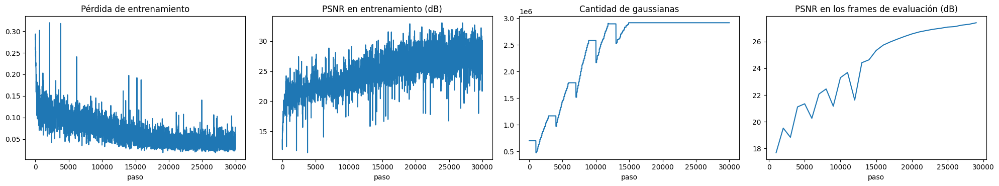

In [14]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

try:
    ea = EventAccumulator(RUN, size_guidance={"scalars": 0})
    ea.Reload()
    tags = ea.Tags()["scalars"]
    print("curvas guardadas:", tags)

    # (palabras que tiene que tener el nombre de la curva, palabras que no, título del gráfico)
    paneles = [(["train loss"], ["dict"], "Pérdida de entrenamiento"),
               (["train metrics", "psnr"], [], "PSNR en entrenamiento (dB)"),
               (["gaussian_count"], [], "Cantidad de gaussianas"),
               (["all images", "psnr"], [], "PSNR en los frames de evaluación (dB)")]

    fig, ejes = plt.subplots(1, 4, figsize=(20, 3.8))
    for a, (pide, no_pide, titulo) in zip(ejes, paneles):
        elegidas = [t for t in tags if all(p in t.lower() for p in pide) and not any(p in t.lower() for p in no_pide)]
        if elegidas:
            ev = ea.Scalars(elegidas[0])
            a.plot([e.step for e in ev], [e.value for e in ev])
        a.set_title(titulo); a.set_xlabel("paso")
    plt.tight_layout()
    plt.savefig(f"{SALIDA}/curvas_entrenamiento.png", dpi=100)
    plt.show()
except Exception as e:
    print("no pude leer las curvas de TensorBoard:", e)

### Un parche necesario antes de evaluar y exportar
Las versiones nuevas de PyTorch (≥ 2.6) cargan los checkpoints con `weights_only=True` por defecto, y el checkpoint de Nerfstudio guarda objetos propios, así que `ns-eval` y `ns-export` fallan al leerlo. El parche agrega `weights_only=False` en la línea que carga el checkpoint (es seguro porque el checkpoint lo generamos nosotros).

In [15]:
import nerfstudio

ruta = os.path.join(os.path.dirname(nerfstudio.__file__), "utils", "eval_utils.py")
texto = open(ruta).read()
viejo = 'loaded_state = torch.load(load_path, map_location="cpu")'
nuevo = 'loaded_state = torch.load(load_path, map_location="cpu", weights_only=False)'
if viejo in texto:
    open(ruta, "w").write(texto.replace(viejo, nuevo))
    print("parche aplicado")
else:
    print("no hace falta el parche (ya estaba aplicado o esta versión de Nerfstudio no lo necesita)")

parche aplicado


## 5. Evaluación en frames que no se usaron para entrenar
`ns-eval` renderiza la escena desde la pose de cada frame de evaluación y compara con la foto real:

- **PSNR** (dB): basado en el error cuadrático medio entre las dos imágenes. Más alto es mejor.
- **SSIM** (0 a 1): similitud de estructura (luminancia, contraste, bordes). Más alto es mejor.
- **LPIPS**: distancia perceptual calculada con una red neuronal, parecida a "cuánto se nota la diferencia a simple vista". **Más bajo** es mejor.

**Ojo con cómo interpretar los números:** los frames de evaluación están intercalados entre los de entrenamiento, o sea que son vecinos muy cercanos de frames que la red ya vio. Las métricas son por eso algo optimistas respecto de lo que pasaría mirando la escena desde un punto de vista muy distinto al de la filmación.

Abajo se muestran algunas comparaciones: a la izquierda la **foto real** y a la derecha el **render**.

In [16]:
!rm -rf /content/eval
!mkdir -p /content/eval/imagenes
!ns-eval --load-config "{CONFIG}" --output-path /content/eval/metricas.json --render-output-path /content/eval/imagenes

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
I0000 00:00:1794677786.174328   50568 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794677786.265757   50568 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/local/lib/python3.13/dist-packages/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` in

In [17]:
with open("/content/eval/metricas.json") as f:
    M = json.load(f)["results"]
for k, v in M.items():
    print("%-18s %s" % (k, round(v, 4) if isinstance(v, float) else v))

RESUMEN["psnr_dB"] = round(float(M["psnr"]), 2) if "psnr" in M else None
RESUMEN["ssim"] = round(float(M["ssim"]), 3) if "ssim" in M else None
RESUMEN["lpips"] = round(float(M["lpips"]), 3) if "lpips" in M else None

psnr               27.3579
psnr_std           2.5515
ssim               0.8906
ssim_std           0.0508
lpips              0.1248
lpips_std          0.0573
num_rays_per_sec   1371070.0
num_rays_per_sec_std 160492.2656
fps                0.9538
fps_std            0.1116


frames de evaluación renderizados: 89


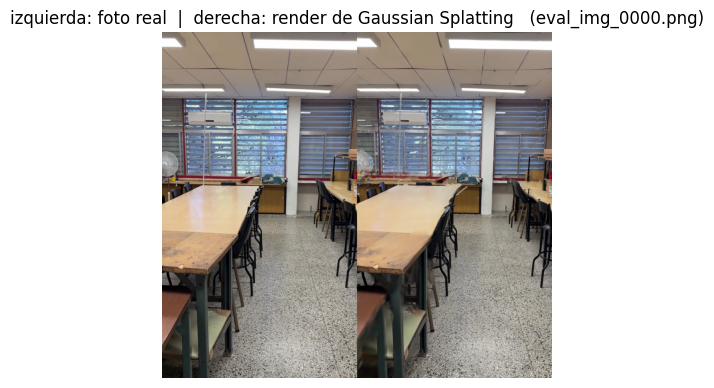

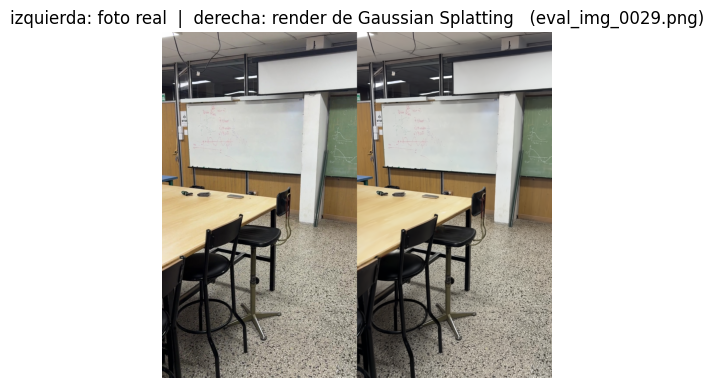

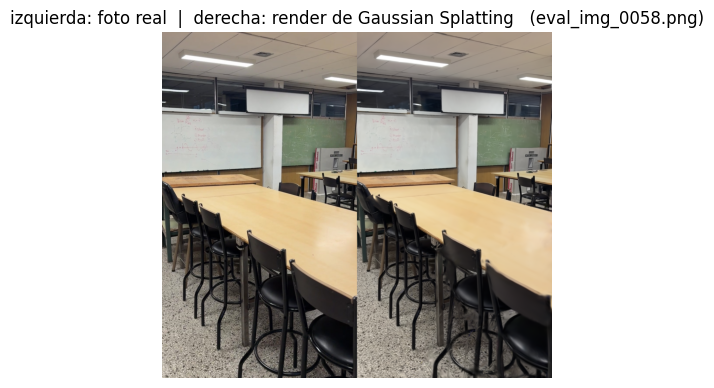

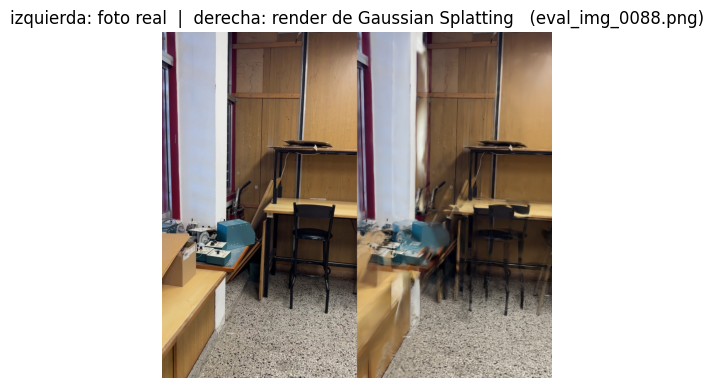

In [18]:
imgs = sorted(glob.glob("/content/eval/imagenes/*"))
RESUMEN["frames_de_evaluacion"] = len(imgs)
print("frames de evaluación renderizados:", len(imgs))

for i in np.linspace(0, len(imgs) - 1, 4).astype(int):
    plt.figure(figsize=(14, 4.5))
    plt.imshow(plt.imread(imgs[i]))
    plt.axis("off")
    plt.title("izquierda: foto real  |  derecha: render de Gaussian Splatting   (" + os.path.basename(imgs[i]) + ")")
    plt.show()

## 6. Recorrido renderizado
`ns-render interpolate` mueve una cámara virtual entre las poses de los frames de evaluación y renderiza cada posición. Así vemos la escena "volando" por el aula. Se guarda la versión completa y se incrusta en el cuaderno una versión liviana (720 px de ancho).

In [19]:
!rm -rf /content/render
!mkdir -p /content/render
!ns-render interpolate --load-config "{CONFIG}" --output-path /content/render/recorrido.mp4 --interpolation-steps 5
# versión liviana para incrustar en el cuaderno
!ffmpeg -loglevel error -y -i /content/render/recorrido.mp4 -vf scale=720:-2 -c:v libx264 -pix_fmt yuv420p -crf 28 /content/render/recorrido_liviano.mp4

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
I0000 00:00:1794677925.878468   51256 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794677925.964375   51256 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/local/lib/python3.13/dist-packages/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` in

In [20]:
from IPython.display import HTML
from base64 import b64encode

datos_video = open("/content/render/recorrido_liviano.mp4", "rb").read()
print("tamaño del video incrustado: %.1f MB" % (len(datos_video) / 1e6))
HTML('<video width="560" controls loop><source src="data:video/mp4;base64,' + b64encode(datos_video).decode() + '" type="video/mp4"></video>')

tamaño del video incrustado: 7.6 MB


## 7. Exportar y analizar las gaussianas
`ns-export gaussian-splat` guarda la escena como un archivo `.ply` donde **cada fila es una gaussiana** (posición, escala, rotación, opacidad y coeficientes de color). Ese archivo se puede abrir en visores web de splats, por ejemplo arrastrándolo a [SuperSplat](https://superspl.at/editor), y es el entregable 3D del proyecto.

Abajo lo leemos y analizamos: cuántas gaussianas hay y cómo se distribuyen su posición y su opacidad.

In [21]:
!ns-export gaussian-splat --load-config "{CONFIG}" --output-dir /content/resultados/splat
!ls -lh /content/resultados/splat

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
I0000 00:00:1794677987.423807   51741 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794677987.508416   51741 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/local/lib/python3.13/dist-packages/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` in

In [22]:
# Lee el .ply de gaussianas sin cargarlo entero en memoria (son cientos de MB)
def leer_ply(ruta):
    nombres = []
    with open(ruta, "rb") as f:
        while True:
            linea = f.readline().decode().strip()
            if linea.startswith("element vertex"):
                n = int(linea.split()[-1])
            elif linea.startswith("property"):
                assert linea.split()[1] == "float", "se esperaban solo propiedades float"
                nombres.append(linea.split()[-1])
            elif linea == "end_header":
                break
        inicio = f.tell()
    datos = np.memmap(ruta, dtype="<f4", mode="r", offset=inicio, shape=(n, len(nombres)))
    return datos, nombres

archivo: /content/resultados/splat/splat.ply
cantidad de gaussianas: 2858423 (2.86 millones) | tamaño del archivo: 709 MB
propiedades por gaussiana: 62
gaussianas con opacidad < 0.1: 12.1 %
tamaño mediano de una gaussiana (unidades internas de Nerfstudio): 0.0017


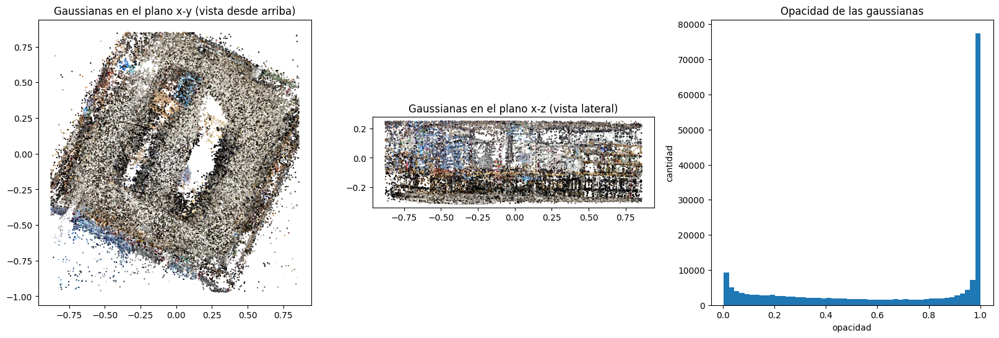

In [23]:
ply = max(glob.glob("/content/resultados/splat/*.ply"), key=os.path.getmtime)
datos, nombres = leer_ply(ply)
c = {n: i for i, n in enumerate(nombres)}
N = len(datos)
RESUMEN["gaussianas"] = int(N)
RESUMEN["tamano_ply_MB"] = round(os.path.getsize(ply) / 1e6)
print("archivo:", ply)
print("cantidad de gaussianas: %d (%.2f millones) | tamaño del archivo: %.0f MB" % (N, N / 1e6, os.path.getsize(ply) / 1e6))
print("propiedades por gaussiana:", len(nombres))

# graficar millones de puntos es lento: trabajamos con una muestra al azar de 200 mil
rng = np.random.default_rng(0)
muestra = np.sort(rng.choice(N, size=min(N, 200000), replace=False))
m = np.array(datos[muestra])
xyz = m[:, [c["x"], c["y"], c["z"]]]
opacidad = 1 / (1 + np.exp(-m[:, c["opacity"]]))                        # el .ply guarda la opacidad como logit
escala = np.exp(m[:, [c["scale_0"], c["scale_1"], c["scale_2"]]])       # y la escala como logaritmo
rgb = np.clip(0.5 + 0.28209479 * m[:, [c["f_dc_0"], c["f_dc_1"], c["f_dc_2"]]], 0, 1)   # color (armónico esférico de orden 0)

RESUMEN["gaussianas_casi_transparentes_%"] = round(float(100 * (opacidad < 0.1).mean()), 1)
print("gaussianas con opacidad < 0.1: %.1f %%" % RESUMEN["gaussianas_casi_transparentes_%"])
print("tamaño mediano de una gaussiana (unidades internas de Nerfstudio): %.4f" % np.median(escala.max(axis=1)))

# para dibujar nos quedamos con las más opacas y sin outliers
op = opacidad > 0.3
lo, hi = np.percentile(xyz[op], 1, axis=0), np.percentile(xyz[op], 99, axis=0)
v = op & np.all((xyz >= lo) & (xyz <= hi), axis=1)

fig, ax = plt.subplots(1, 3, figsize=(20, 6))
ax[0].scatter(xyz[v, 0], xyz[v, 1], c=rgb[v], s=0.5)
ax[0].set_aspect("equal"); ax[0].set_title("Gaussianas en el plano x-y (vista desde arriba)")
ax[1].scatter(xyz[v, 0], xyz[v, 2], c=rgb[v], s=0.5)
ax[1].set_aspect("equal"); ax[1].set_title("Gaussianas en el plano x-z (vista lateral)")
ax[2].hist(opacidad, bins=50)
ax[2].set_title("Opacidad de las gaussianas"); ax[2].set_xlabel("opacidad"); ax[2].set_ylabel("cantidad")
plt.savefig(f"{SALIDA}/gaussianas.png", dpi=100)
plt.show()

## 8. Resumen y guardado de resultados
Juntamos todos los números del cuaderno en una tabla y copiamos los resultados a Google Drive (el `.ply` pesa cientos de MB, por eso va a Drive y no se descarga directo).

In [24]:
import pandas as pd

nombres_lindos = {
    "frames_extraidos": "Frames extraídos del video",
    "frames_borrosos_%": "Frames borrosos (%)",
    "camaras_con_pose": "Frames con pose estimada por COLMAP",
    "puntos_3d_colmap": "Puntos 3D de la nube dispersa",
    "error_reproyeccion_medio_px": "Error de reproyección medio (px)",
    "track_medio_imagenes": "Imágenes por punto 3D (promedio)",
    "tiempo_colmap_min": "Tiempo de COLMAP (min)",
    "tiempo_entrenamiento_min": "Tiempo de entrenamiento (min)",
    "gaussianas": "Cantidad de gaussianas",
    "gaussianas_casi_transparentes_%": "Gaussianas casi transparentes, opacidad < 0.1 (%)",
    "tamano_ply_MB": "Tamaño del .ply (MB)",
    "frames_de_evaluacion": "Frames de evaluación",
    "psnr_dB": "PSNR (dB)",
    "ssim": "SSIM",
    "lpips": "LPIPS (menor es mejor)",
}
tabla = pd.DataFrame({"Medida": [nombres_lindos.get(k, k) for k in RESUMEN], "Valor": pd.Series(list(RESUMEN.values()), dtype=object)})
json.dump(RESUMEN, open(f"{SALIDA}/resumen.json", "w"), indent=2, ensure_ascii=False)
tabla

,Medida,Valor
0,Tiempo de COLMAP (min),106.9
1,Frames extraídos del video,899
2,Frames borrosos (%),4.6
3,Frames con pose estimada por COLMAP,899
4,Puntos 3D de la nube dispersa,700338
5,Error de reproyección medio (px),0.356
6,Imágenes por punto 3D (promedio),9.0
7,Tiempo de entrenamiento (min),71.3
8,PSNR (dB),27.36
9,SSIM,0.891


In [25]:
# Copiamos todo lo que vamos a entregar a la carpeta de resultados
shutil.copy(CONFIG, f"{SALIDA}/config.yml")
shutil.copy("/content/eval/metricas.json", f"{SALIDA}/metricas.json")
shutil.copy("/content/render/recorrido.mp4", f"{SALIDA}/recorrido.mp4")
shutil.copy(f"{DATA}/transforms.json", f"{SALIDA}/transforms.json")
shutil.copy("/content/entrenamiento.log", f"{SALIDA}/entrenamiento.log")
shutil.copytree("/content/eval/imagenes", f"{SALIDA}/comparaciones_real_vs_render", dirs_exist_ok=True)

# y a Google Drive
DESTINO = "/content/drive/MyDrive/resultados_gaussian_splatting"
!mkdir -p "{DESTINO}"
!cp -r /content/resultados/. "{DESTINO}/"
!ls -lh "{DESTINO}"

total 27M
drwx------ 2 root root 4.0K Nov 14 17:42 comparaciones_real_vs_render
-rw------- 1 root root 7.6K Nov 14 17:42 config.yml
-rw------- 1 root root  77K Nov 14 17:42 curvas_entrenamiento.png
-rw------- 1 root root 4.5M Nov 14 17:42 entrenamiento.log
-rw------- 1 root root  29K Nov 14 17:42 error_reproyeccion.png
-rw------- 1 root root 778K Nov 14 17:42 frames.png
-rw------- 1 root root 612K Nov 14 17:42 gaussianas.png
-rw------- 1 root root  535 Nov 14 17:42 metricas.json
-rw------- 1 root root  63K Nov 14 17:42 nitidez.png
-rw------- 1 root root  19M Nov 14 17:42 recorrido.mp4
-rw------- 1 root root  428 Nov 14 17:42 resumen.json
-rw------- 1 root root 689K Nov 14 17:42 sfm.png
drwx------ 2 root root 4.0K Nov 14 17:42 splat
-rw------- 1 root root 552K Nov 14 17:42 transforms.json


## 9. Discusión y limitaciones

**Qué se logró.** Un pipeline reproducible que va de **un video de celular a un modelo 3D renderizable** de un aula, sin LiDAR y sin calibrar la cámara: SfM con COLMAP para obtener las poses y la nube dispersa, y 3DGS para el modelo fotorrealista. Las métricas del paso 5 y el error de reproyección del paso 3 cuantifican la calidad.

**Causas habituales de artefactos** (manchas, "flotantes", zonas borrosas) y cómo verlas en los resultados de este cuaderno:
- **Superficies sin textura** (paredes lisas, pizarrón, piso uniforme): SIFT casi no encuentra puntos, la nube dispersa queda con huecos y las gaussianas arrancan mal ubicadas. Se ve en la nube dispersa del paso 3.
- **Ventanas, reflejos y cambios de exposición**: 3DGS asume una escena estática con apariencia casi constante entre vistas; una ventana a contraluz o la exposición automática del celular rompen esa suposición.
- **Frames borrosos** (paso 2): dan correspondencias malas y texturas lavadas.
- **Poca cobertura angular**: las zonas vistas desde pocos ángulos quedan mal definidas. Ocurre sobre todo si se filma "girando parado" en vez de moverse alrededor.
- **Métricas optimistas**: los frames de evaluación son vecinos de los de entrenamiento (ver paso 5).
- **Escala**: con una sola cámara el modelo no está en metros (ambigüedad de escala del SfM monocular); haría falta una medida externa.

**Mejoras posibles.** Filmar más lento, con exposición y foco bloqueados, con buena iluminación y recorriendo la escena desde varios ángulos y alturas; filmar zonas con más textura o agregar objetos con textura; descartar los frames borrosos antes de COLMAP; y, para medir una mejora real, evaluar con frames tomados de una pasada de video distinta a la de entrenamiento.

**Relación con el otro cuaderno del proyecto.** El Gaussian Splatting da un render muy fiel, pero **no es una malla sólida**: no sirve directamente para colisiones en un simulador. Para eso el cuaderno de *gemelo digital* parte del mismo SfM y construye una malla (TSDF + marching cubes) exportable a ROS/Gazebo.

## Bibliografía
- Kerbl, B., Kopanas, G., Leimkühler, T., & Drettakis, G. (2023). *3D Gaussian Splatting for Real-Time Radiance Field Rendering*. ACM Transactions on Graphics, 42(4).
- Schönberger, J. L., & Frahm, J. M. (2016). *Structure-from-Motion Revisited*. CVPR.
- Pan, L., Baráth, D., Pollefeys, M., & Schönberger, J. L. (2024). *Global Structure-from-Motion Revisited* (GLOMAP). ECCV.
- Tancik, M. et al. (2023). *Nerfstudio: A Modular Framework for Neural Radiance Field Development*. SIGGRAPH.
- Ye, V. et al. (2024). *gsplat: An Open-Source Library for Gaussian Splatting*.
- Lowe, D. G. (2004). *Distinctive Image Features from Scale-Invariant Keypoints*. International Journal of Computer Vision.
- Wang, Z., Bovik, A. C., Sheikh, H. R., & Simoncelli, E. P. (2004). *Image Quality Assessment: From Error Visibility to Structural Similarity*. IEEE Transactions on Image Processing.
- Zhang, R., Isola, P., Efros, A. A., Shechtman, E., & Wang, O. (2018). *The Unreasonable Effectiveness of Deep Features as a Perceptual Metric*. CVPR.